<h1><center>Распознавание речи</h2></center>

<h2>Загрузка и предобработка данных

In [1]:
path_to_data = 'D:/MIREA/DPO/Learning/Datasets/Audio_MNIST/data'

In [2]:
import os
import shutil
import random
from tqdm import tqdm


path_to_train = path_to_data + '/train'
path_to_valid = path_to_data + '/valid'

ratio_split = .2

In [3]:
# os.makedirs(path_to_train, exist_ok=True)
# os.makedirs(path_to_valid, exist_ok=True)

# subfolders = [
#     f for f in os.listdir(path_to_data)
#     if os.path.isdir(os.path.join(path_to_data, f)) and f not in ['train', 'valid']
# ]

# print('Num subfolders: ', len(subfolders))

# for folder in tqdm(subfolders):
#     path_to_folder = os.path.join(path_to_data, folder)

#     files = [f for f in os.listdir(path_to_folder) if f.endswith('.wav')]

#     if not files:
#         print(f'Folder {folder:>2s}: not .wav files')
#         continue

#     random.shuffle(files)

#     split_index = int(len(files) * ratio_split)

#     valid_files = files[:split_index]
#     train_files = files[split_index:]

#     for file_name in valid_files:
#         src = os.path.join(path_to_folder, file_name)
#         dst = os.path.join(path_to_valid, file_name)
#         shutil.move(src, dst)

#     for file_name in train_files:
#         src = os.path.join(path_to_folder, file_name)
#         dst = os.path.join(path_to_train, file_name)
#         shutil.move(src, dst)

# print('End of transparating')

In [4]:
count_numbers = {
    'train': {k: 0 for k in range(10)},
    'valid': {k: 0 for k in range(10)}
}


for folder_path in [path_to_train, path_to_valid]:
    files = os.listdir(folder_path)
    
    for file in files:
        number, num_folder, num_record = file[:-4].split('_')
        count_numbers[folder_path[-5:]][int(number)] += 1


print(f'Train: {count_numbers["train"]}')
print(f'Valid: {count_numbers["valid"]}')

for dataset_name in count_numbers.keys():
    dataset = count_numbers[dataset_name]
    
    sum_records = sum(dataset.values())

    out_ratio = {k: round(v / sum_records, 3) for k, v in dataset.items()}
    print(f'{dataset_name.capitalize()}: {out_ratio}')


Train: {0: 2358, 1: 2402, 2: 2384, 3: 2407, 4: 2417, 5: 2396, 6: 2385, 7: 2405, 8: 2423, 9: 2423}
Valid: {0: 642, 1: 598, 2: 616, 3: 593, 4: 583, 5: 604, 6: 615, 7: 595, 8: 577, 9: 577}
Train: {0: 0.098, 1: 0.1, 2: 0.099, 3: 0.1, 4: 0.101, 5: 0.1, 6: 0.099, 7: 0.1, 8: 0.101, 9: 0.101}
Valid: {0: 0.107, 1: 0.1, 2: 0.103, 3: 0.099, 4: 0.097, 5: 0.101, 6: 0.102, 7: 0.099, 8: 0.096, 9: 0.096}


In [5]:
file = 'dlksd.wav'
file[-5:]

'd.wav'

In [6]:
from collections import defaultdict
from itertools import islice
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from IPython.display import clear_output
from IPython import display
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import trange

In [7]:
path_to_data = 'D:/MIREA/DPO/Learning/Datasets/RussianAudioMNIST/numbers'

<h2>Обработка данных

In [8]:
class SpeechDaataset(Dataset):
    SAMPLE_RATE = 16000
    _ROOT_PREFIX = path_to_data

    def __init__(self, path_to_csv: str) -> None:
        self.path_to_csv = path_to_csv
        self.csv: pd.DataFrame = pd.read_csv(path_to_csv)

    @staticmethod
    def number2digits(number: np.ndarray) -> torch.Tensor:
        digits = list(map(int, list(str(number))))
        return torch.LongTensor(digits)

    def __getitem__(self, index: int) -> dict[str, Any]:
        output = self.csv.iloc[index]

        if len(output) == 3:
            path, gender, number = output
            y = self.number2digits(number)
        else:
            (path, ) = output
            y = torch.LongTensor([-1])

        path = os.path.join(self._ROOT_PREFIX, path)

        wav, sr = torchaudio.load(path)
        if sr != self.SAMPLE_RATE:
            resampler = torchaudio.transforms.Resample(sr, self.SAMPLE_RATE)
            wav = resampler(wav)

        wav = wav.squeeze()
        instance = {'path': path, 'x': wav, 'y': y}
        return instance

    def __len__(self) -> int:
        return self.csv.shape[0]

In [9]:
dataset = SpeechDaataset(path_to_data + '/train.csv')
train_ratio = .9
train_size = int(len(dataset) * train_ratio)

random_indexes = torch.randperm(len(dataset)).tolist()
train_dataset = Subset(dataset, random_indexes[:train_size])
valid_dataset = Subset(dataset, random_indexes[train_size:])

In [10]:
len(train_dataset), len(valid_dataset)

(8100, 900)

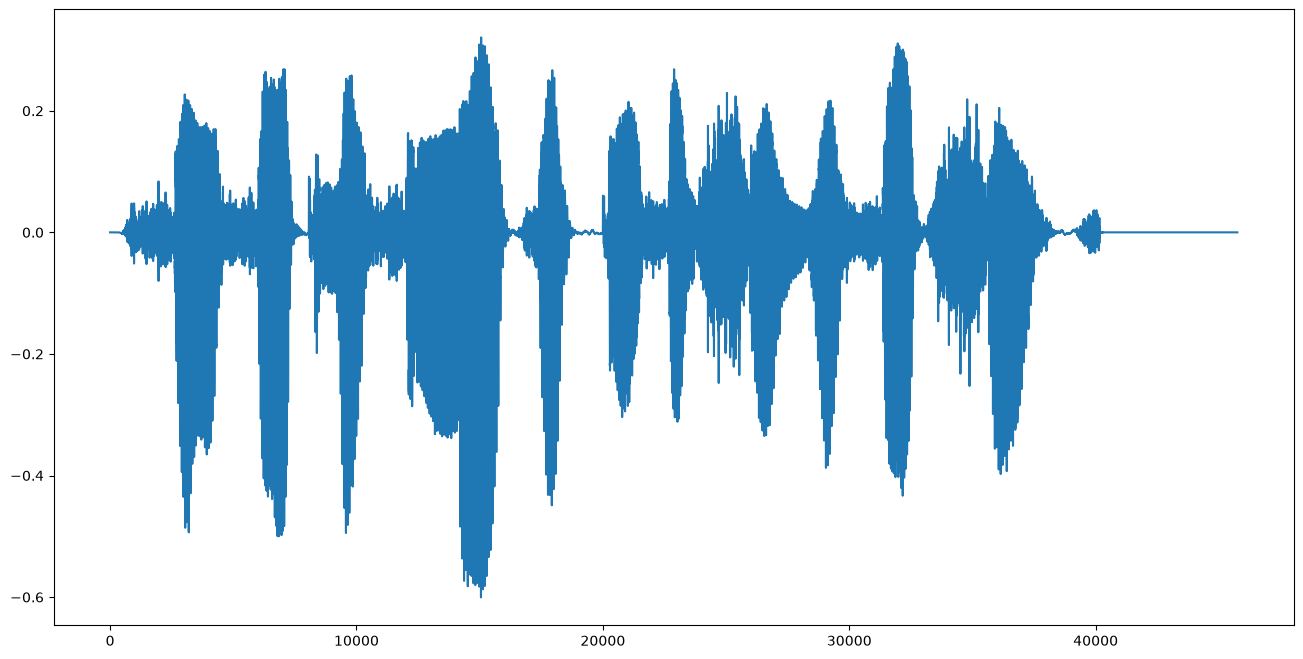

In [11]:
instance = train_dataset[0]
plt.figure(figsize=(16, 8))
plt.plot(instance['x'])

display.Audio(instance['x'], rate=dataset.SAMPLE_RATE)

In [12]:
instance['y']

tensor([7, 1, 8, 0, 6, 6])

<h2>Padding</h2>

- если короткое, заполняем 10

In [13]:
class PaddingCollator:
    def __call__(self, instances) -> dict[str, Any]:
        batch_size = len(instances)
        x_len = torch.LongTensor([instance['x'].size(0) for instance in instances])
        y_len = torch.LongTensor([instance['y'].size(0) for instance in instances])
        path = [instance['path'] for instance in instances]
        
        x = torch.zeros(batch_size, max(x_len), dtype=torch.float32)
        y = torch.zeros(batch_size, max(y_len), dtype=torch.long)
        y.fill_(10)

        for i, instance in enumerate(instances):
            x[i, :x_len[i]] = instance['x']
            y[i, :y_len[i]] = instance['y']

        instance = {'x': x, 'y': y, 'x_len': x_len, 'y_len': y_len, 'path': path}

        return instance

In [14]:
train_loader = DataLoader(train_dataset, batch_size=2, collate_fn=PaddingCollator(),
                          shuffle=True, pin_memory=True, drop_last=True)
valid_loader = DataLoader(valid_dataset, batch_size=2, collate_fn=PaddingCollator(),
                          pin_memory=True)

In [15]:
batch = list(islice(valid_loader, 1))[0]
batch

{'x': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 'y': tensor([[9, 1, 3, 1, 7, 2],
         [5, 9, 8, 0, 1, 8]]),
 'x_len': tensor([43664, 45684]),
 'y_len': tensor([6, 6]),
 'path': ['D:/MIREA/DPO/Learning/Datasets/RussianAudioMNIST/numbers\\train/011d8d3d8d.wav',
  'D:/MIREA/DPO/Learning/Datasets/RussianAudioMNIST/numbers\\train/06d2bcdf90.wav']}

<h2>Вычисление признаков</h2>

Нарезаем исходную запись на кусочки и делаем преобразование Фурье.
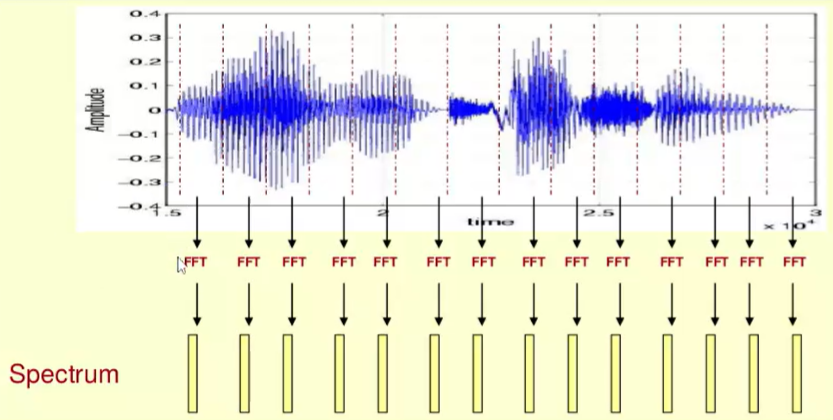
А далее каждый кусочек раскладываем на спектр (строим спектрограмму). А далее неоспектрограмму.
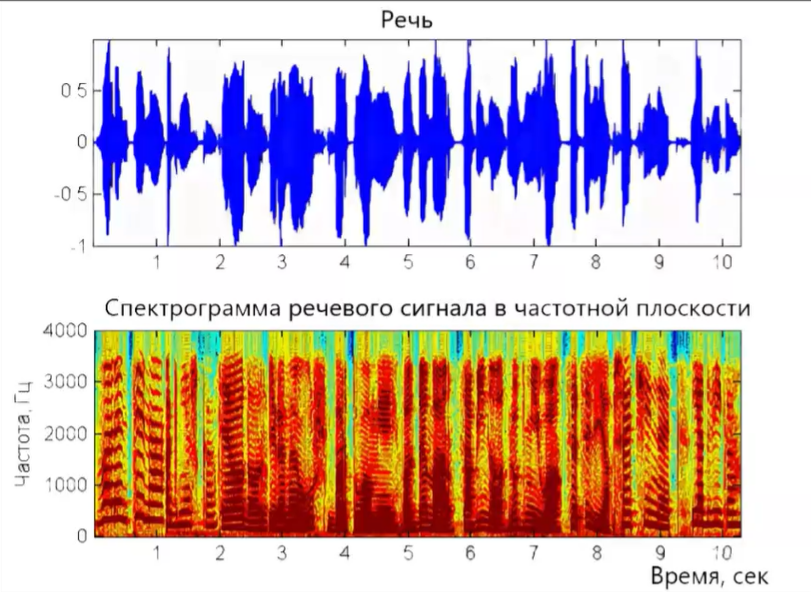
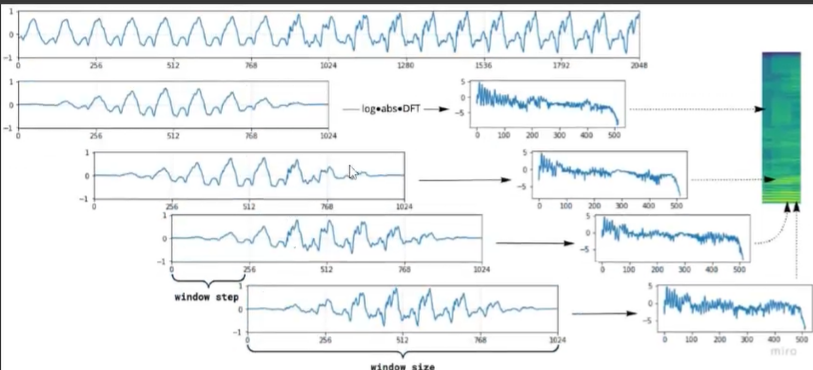

In [16]:
instance = train_dataset[31]
wav = instance['x']

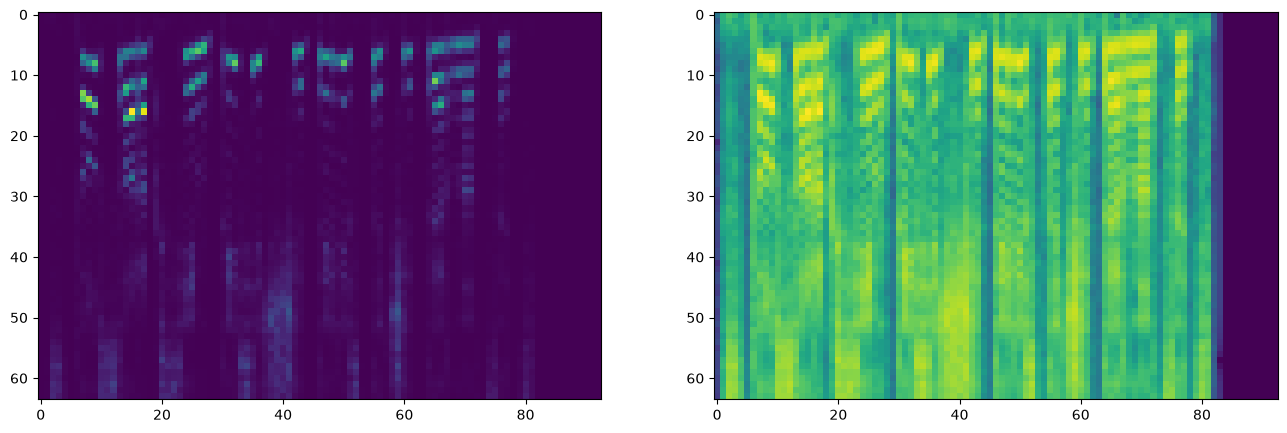

In [17]:
from torchaudio.transforms import MelSpectrogram


featurizer = MelSpectrogram(sample_rate=train_dataset.dataset.SAMPLE_RATE,
                            n_fft=512,
                            win_length=512,
                            hop_length=512,
                            n_mels=64,
                            power=1)

def apply_compression(melspec):
    '''
    Добавляем небольшой шум, чтобы не быть в 0
    '''
    return torch.log(melspec.clamp(1e-5))


fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(featurizer(wav))
axes[1].imshow(apply_compression(featurizer(wav)))

In [18]:
# effects = [
#     ['gain', '-n'],
#     ['pitch', '5']
# ]

# waveform, sample_rate = torchaudio.sox_effects.apply_effects_tensor(
#     featurizer(wav).cpu(), 16000, effects, channels_first=True
# )

# wav_tensor = featurizer(wav).cpu()

# if wav_tensor.nelement() > 0:
#     max_val = torch.max(torch.abs(wav_tensor))
#     if max_val > 0:
#         wav_tensor = wav_tensor / max_val

# waveform = torchaudio.functional.pitch_shift(
#     waveform=wav_tensor,
#     sample_rate=16000,
#     n_steps=5
# )

# plt.imshow(waveform)



In [19]:
class Featurizer(nn.Module):
    def __init__(self):
        super().__init__()

        self.featurizer = MelSpectrogram(sample_rate=train_dataset.dataset.SAMPLE_RATE,
                                        n_fft=512,
                                        win_length=512,
                                        hop_length=512,
                                        n_mels=64,
                                        power=1)
        
    def forward(self, x, x_len=None):
        x = self.featurizer(x)
        x = apply_compression(x)

        if x_len is not None:
            x_len = ((x_len + 1).float() / self.featurizer.hop_length).ceil().long()
            return x, x_len
        
        return x

<h2>Написание модели<h2>

In [20]:
class QuartzBlock(nn.Module):
    def __init__(self, in_channels: int, hidden_channels: int,
                 kernel_size: int=33, repeat: int=4) -> None:
        super().__init__()
        self.repeat = repeat
        self.blocks = nn.ModuleList(
            [nn.ModuleList([nn.Conv1d(in_channels=in_channels if i == 0 else hidden_channels,
                                      out_channels=hidden_channels,
                                      kernel_size=kernel_size,
                                      groups=in_channels if i == 0 else hidden_channels,
                                      padding=kernel_size // 2,
                                      bias=False),
                            nn.Conv1d(hidden_channels, hidden_channels, kernel_size=1, bias=False),
                            nn.BatchNorm1d(hidden_channels),
                            nn.ReLU(),
                            nn.Dropout(p=.2, inplace=False)]) for i in range(repeat)]
        )
        self.res_conv = nn.Sequential(nn.Conv1d(in_channels, hidden_channels, kernel_size=1, bias=False),
                                      nn.BatchNorm1d(hidden_channels))
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_initial = x
        for i, block in enumerate(self.blocks):
            for j, layer in enumerate(block):
                if not (i == len(self.blocks) - 1 and j == (len(block) - 1)):
                    x = layer(x)
                else:
                    x = x + self.res_conv(x_initial)
                    x = layer(x)
        return x
    
class DummyModel(nn.Module):
    def __init__(self, in_channels: int, hidden_channels: int, out_channels: int) -> None:
        super().__init__()
        self.prenet = nn.Sequential(nn.Conv1d(in_channels, hidden_channels, kernel_size=33, padding=33 // 2,
                                              stride=2, bias=False),
                                    nn.Conv1d(hidden_channels, hidden_channels,kernel_size=1, bias=False),
                                    nn.BatchNorm1d(hidden_channels),
                                    nn.ReLU(),
                                    nn.Dropout(p=.2, inplace=False))
        self.net = nn.Sequential(QuartzBlock(hidden_channels, hidden_channels),
                                 QuartzBlock(hidden_channels, hidden_channels * 2),
                                 nn.Conv1d(hidden_channels * 2, hidden_channels * 2, kernel_size=33, padding=33 // 2,
                                           stride=2, bias=False),
                                nn.Conv1d(hidden_channels * 2, hidden_channels * 2, kernel_size=1, bias=False),
                                nn.BatchNorm1d(hidden_channels * 2),
                                nn.ReLU(),
                                QuartzBlock(hidden_channels * 2, hidden_channels * 4))
        self.classifier = nn.Sequential(nn.Conv1d(hidden_channels * 4, out_channels, kernel_size=1, bias=False),
                                        nn.LogSoftmax(dim=1))
        
    def forward(self, x: torch.Tensor, x_len: int) -> tuple[torch.Tensor, int]:
        x = self.prenet(x)
        x = self.net(x)
        out = self.classifier(x)
        return out, x_len // 4

<h2>Метрика качества

In [21]:
import Levenshtein


def ctc_decode(sequence, blank_symbol=10):
    current = []
    for i in range(0, len(sequence)):
        symbol = sequence[i]
        if i > 0 and symbol == sequence[i - 1]:
            continue
        if symbol == blank_symbol:
            continue
        current.append(str(int(symbol)))
    text = ''.join(current)
    return text

def calculate_cer(targets, decodings, padding_value=10):
    cer = 0.0
    targets = targets.detach().cpu().tolist()

    pairs = []
    for target, d in zip(targets, decodings):
        target = [c for c in target if c != padding_value]
        target = ''.join(map(str, target))

        decoding = ctc_decode(d.tolist())
        cer += min(1, Levenshtein.distance(target, decoding) / (len(decoding) + 1e-7))
        pairs.append(target + '\t\t' + decoding)
    return cer / len(targets), pairs

<h2>Обучение

In [22]:
class AverageMeter():
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [23]:
NUM_EPOCHS = 20
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = DummyModel(64, 128, 10 + 1).to(device)
mel_featurizer = Featurizer().to(device)
criterion = nn.CTCLoss(blank=10)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)

In [24]:
print(f'Number of params: {sum(p.numel() for p in model.parameters())}')

Number of params: 4205056


Epoch: 11
Example of prediction  533353 -> 5333539
Example of prediction  813923 -> 8129206


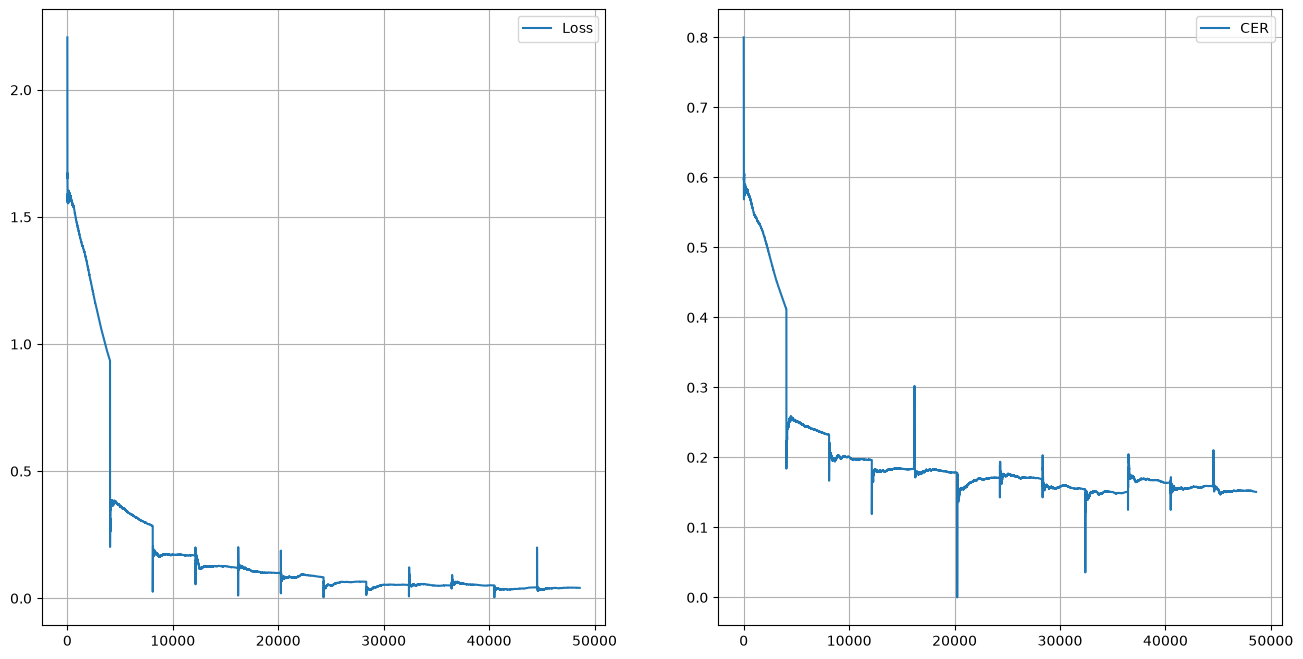

  0%|          | 0/4050 [00:00<?, ?it/s]

In [ ]:
from tqdm.notebook import tqdm


pitch_shift_transform = torchaudio.transforms.PitchShift(
    sample_rate=16000, n_steps=5
).to(device)
# effects = [
#     ['gain', '-n'],
#     ['pitch', '5']
# ]

history = defaultdict(list)
accumulation_steps = 16

for epoch in trange(NUM_EPOCHS):
    average_cer = AverageMeter()
    average_loss = AverageMeter()

    for num_batch, batch in tqdm(enumerate(train_loader), total=len(train_loader)):
        
        raw_audio = batch['x'].to(device) ###
        x, y = batch['x'].to(device), batch['y'].to(device)
        x_len, y_len = batch['x_len'].to(device), batch['y_len'].to(device)
    

        batch_size = raw_audio.shape[0]
        # batch_size = x.shape[2] ###
        # for i in range(batch_size // 2):
        #     if i % 2 == 0:
        #         tmp, sample_rate = torchaudio.sox_effects.apply_effects_tensor(
        #             x[:, :, i].cpu(), 16000, effects
        #         )
        #         x[:, :, i] = tmp.to(device)   
        # 

        augment_mask = torch.rand(batch_size) < 0.5 
        
        if augment_mask.any():
            audio_to_aug = raw_audio[augment_mask]
            gain_factors = torch.empty(audio_to_aug.shape[0]).uniform_(0.7, 1.3).to(device)
            
            if audio_to_aug.dim() == 3:
                gain_factors = gain_factors.view(-1, 1, 1)
            else:
                gain_factors = gain_factors.view(-1, 1)
                
            audio_to_aug = audio_to_aug * gain_factors
            audio_to_aug = pitch_shift_transform(audio_to_aug)
            raw_audio[augment_mask] = audio_to_aug
        x, x_len = mel_featurizer(x, x_len) 
        log_probs, x_len = model(x, x_len)

        log_probs = log_probs.permute(2, 0, 1)
        loss = criterion(log_probs, y, x_len, y_len)

        loss_scaled = loss / accumulation_steps
        loss_scaled.backward()
        if (num_batch + 1) % accumulation_steps == 0 or (num_batch + 1) == len(train_loader):
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)


        argmax_decoding = log_probs.detach().cpu().argmax(dim=-1).transpose(0, 1)
        cer, pairs = calculate_cer(y, argmax_decoding)
        average_cer.update(cer)
        average_loss.update(loss.item())

        history['loss'].append(average_loss.avg)
        history['cer'].append(average_cer.avg)

    display.clear_output()
    print(f'Epoch: {epoch}')
    for i in range(2):
        print('Example of prediction ', pairs[i].replace('\t\t', ' -> '))
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    axes[0].plot(history['loss'], label='Loss')
    axes[1].plot(history['cer'], label='CER')
    axes[0].legend()
    axes[0].grid()
    axes[1].legend()
    axes[1].grid()
    plt.show()

In [12]:
model

NameError: name 'model' is not defined